# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot decadal change in wind rose for impactful pattern for the four villages
- Lowest Level (~60m) U and V
- Calculate daily wind speed and direction from this that go into wind rose

**Notebook by Alice DuVivier - June 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick
import metpy.calc as mpcalc
from metpy.calc import wind_speed
from metpy.calc import wind_direction
from metpy.units import units
from windrose import WindroseAxes
import math

## Set village and node of choice

In [2]:
# set paired lists name and node of interest
village_names = ['Nome','Savoonga','Gambell','Shishmaref','Unalakleet']
village_lats =  [64.501, 63.694, 63.776, 66.257, 63.879]
village_lons =  [-165.406, -170.479, -171.701, -166.072, -160.790]

# set xloc and yloc values - determined from another notebook finding nearest atmospheric point that is over mostly ocean
village_xlocs = [57,55,55,65,55]
village_ylocs = [98,78,73,95,115]

In [3]:
# set node info - '2a' or '2b'
village_node = '2a'

In [4]:
# set village to read in: 0-3
n = 2

## Load data
- not identical to training data so we can see larger area patterns

In [5]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_single_node/'

In [6]:
# choose data - load zonal wind first
var_in = 'UBOT'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
uwnd = data

In [7]:
# choose data - load meridional wind next
var_in = 'VBOT'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
vwnd = data

In [8]:
# set lat/lon
lat1d = ds.lat
lon1d = ds.lon

## Break Data into decades

In [9]:
# choose subset of decades to do initial analysis
decades = [1950,2000,2050]
decades_str = ['1950','2000','2050']

In [10]:
# data for each decade in subset of decades
mask_1950 = ds.time.where(ds.decades == 1950)
uwnd_1950 = uwnd.where(mask_1950 >= 0, drop=True)
vwnd_1950 = vwnd.where(mask_1950 >= 0, drop=True)
print('number of times in 1950:'+str(len(uwnd_1950.time)))

mask_2000 = ds.time.where(ds.decades == 2000)
uwnd_2000 = uwnd.where(mask_2000 >= 0, drop=True)
vwnd_2000 = vwnd.where(mask_2000 >= 0, drop=True)
print('number of times in 2000:'+str(len(uwnd_2000.time)))

mask_2050 = ds.time.where(ds.decades == 2050)
uwnd_2050 = uwnd.where(mask_2050 >= 0, drop=True)
vwnd_2050 = vwnd.where(mask_2050 >= 0, drop=True)
print('number of times in 2050:'+str(len(uwnd_2050.time)))

number of times in 1950:198
number of times in 2000:270
number of times in 2050:303


## Get data at villages to get distributions

In [11]:
# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# read in xloc and yloc for this village
xloc = village_xlocs[n]
yloc = village_ylocs[n]

# 1950
uwnd_village = uwnd_1950.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_1950 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd_1950.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_1950 = vwnd_village.isel(lat=0,lon=0)

# 2000
uwnd_village = uwnd_2000.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_2000 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd_2000.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_2000 = vwnd_village.isel(lat=0,lon=0)

# 2050
uwnd_village = uwnd_2050.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_2050 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd_2050.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_2050 = vwnd_village.isel(lat=0,lon=0)

Gambell


## Calculate wind speed and direction

In [12]:
import metpy.calc as mpcalc
from metpy.calc import wind_speed
from metpy.calc import wind_direction
from metpy.units import units

In [13]:
# 1950
utmp = uwnd_village_1950.to_numpy()
utmp = utmp * (units.meter / units.second)
vtmp = vwnd_village_1950.to_numpy()
vtmp = vtmp * (units.meter / units.second)
ws_array_1950 = wind_speed(utmp,vtmp)
wd_array_1950 = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_1950 = xr.DataArray(ws_array_1950,dims=('dates'))
wd_1950 = xr.DataArray(wd_array_1950,dims=('dates'))

In [14]:
# 2000
utmp = uwnd_village_2000.to_numpy()
utmp = utmp * (units.meter / units.second)
vtmp = vwnd_village_2000.to_numpy()
vtmp = vtmp * (units.meter / units.second)
ws_array_2000 = wind_speed(utmp,vtmp)
wd_array_2000 = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_2000 = xr.DataArray(ws_array_2000,dims=('dates'))
wd_2000 = xr.DataArray(wd_array_2000,dims=('dates'))

In [15]:
# 2050
utmp = uwnd_village_2050.to_numpy()
utmp = utmp * (units.meter / units.second)
vtmp = vwnd_village_2050.to_numpy()
vtmp = vtmp * (units.meter / units.second)
ws_array_2050 = wind_speed(utmp,vtmp)
wd_array_2050 = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_2050 = xr.DataArray(ws_array_2050,dims=('dates'))
wd_2050 = xr.DataArray(wd_array_2050,dims=('dates'))

## Plot wind data at this village

In [16]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

### Plot wind roses by decade

In [17]:
# define a function for windrose colormap
def truncate_colormap(color, minval=0.0, maxval=1.0, n=100):
    cmap = plt.colormaps.get_cmap(color)
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

In [18]:
# set stuff for wind roses

# truncate colormap
cmap_in = plt.colormaps['GnBu']
cmap = truncate_colormap(cmap_in, 0.1, 0.9)

# Set bins ranges
windRange = np.array([0, 5, 8, 11, 17])

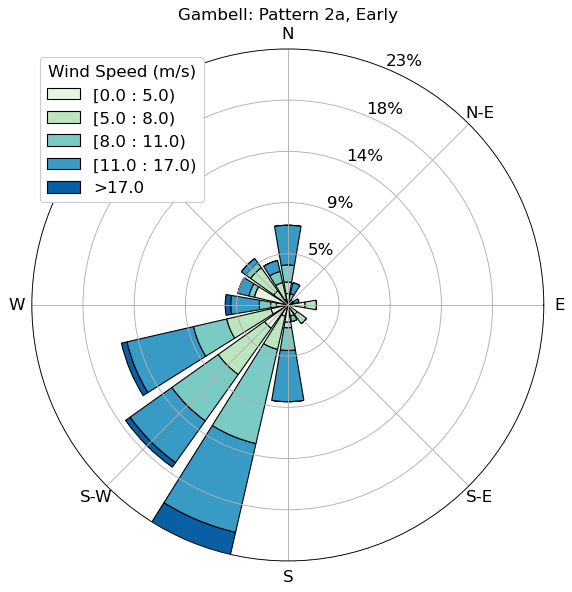

In [19]:
# 1950 wind rose
fout = 'supp_fig_'+village_names[n]+'_node_'+village_node+'_windrose_decadal_1950'

# data to plot
ws = ws_1950
wd = wd_1950
title_str = village_names[n]+': Pattern '+village_node+', Early'

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

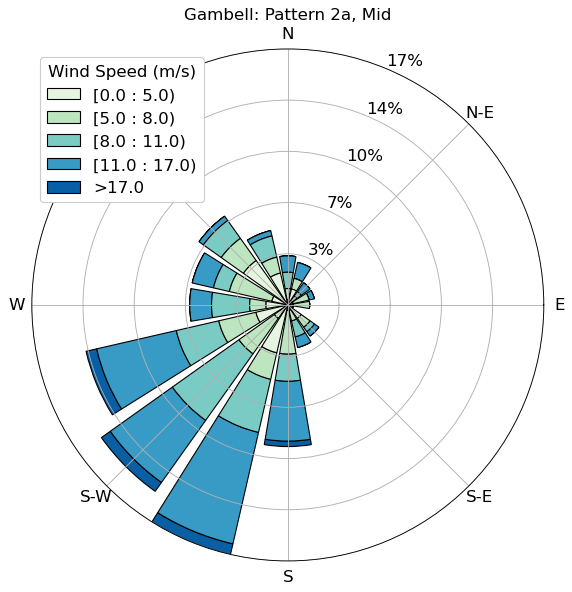

In [20]:
# 2000 wind rose
fout = 'supp_fig_'+village_names[n]+'_node_'+village_node+'_windrose_decadal_2000'

# data to plot
ws = ws_2000
wd = wd_2000
title_str = village_names[n]+': Pattern '+village_node+', Mid'

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)
# close plot
#plt.close()

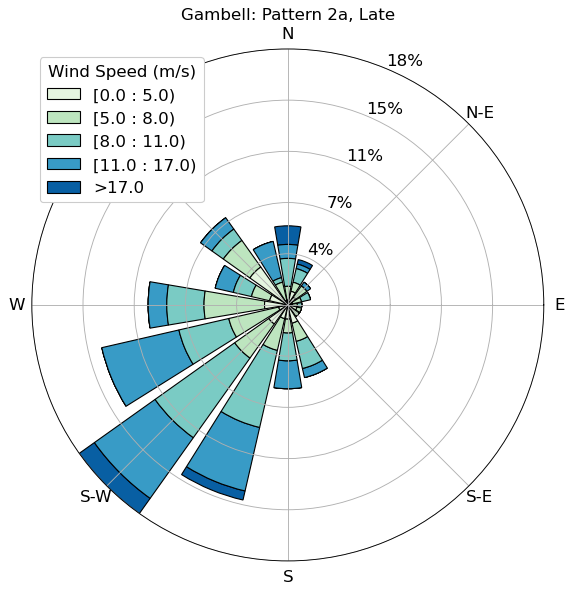

In [21]:
# 2050 wind rose
fout = 'supp_fig_'+village_names[n]+'_node_'+village_node+'_windrose_decadal_2050'

# data to plot
ws = ws_2050
wd = wd_2050
title_str = village_names[n]+': Pattern '+village_node+', Late'

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)
# close plot
#plt.close()